# My first end-to-end project ahihi, I will work with Titanic dataset

## Changelog
### 03/09/2026: Fixes data transform in test set --> No more fake 90%+ accuracy
###             Add passthrough in the pipeline --> No more hidden dropping essential features
###             Add GridSearch/KFolds --> Got a stable accuracy when comes to new data

In [1]:
# Loading libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore')

In [2]:
# Get the data
df = pd.read_csv("train.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df = df.drop(['PassengerId','Name','Ticket','Cabin'] , axis='columns')
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [4]:
df.dropna(subset = ["Embarked"], inplace=True)

In [5]:
df.isna().sum()

Survived      0
Pclass        0
Sex           0
Age         177
SibSp         0
Parch         0
Fare          0
Embarked      0
dtype: int64

## EDA

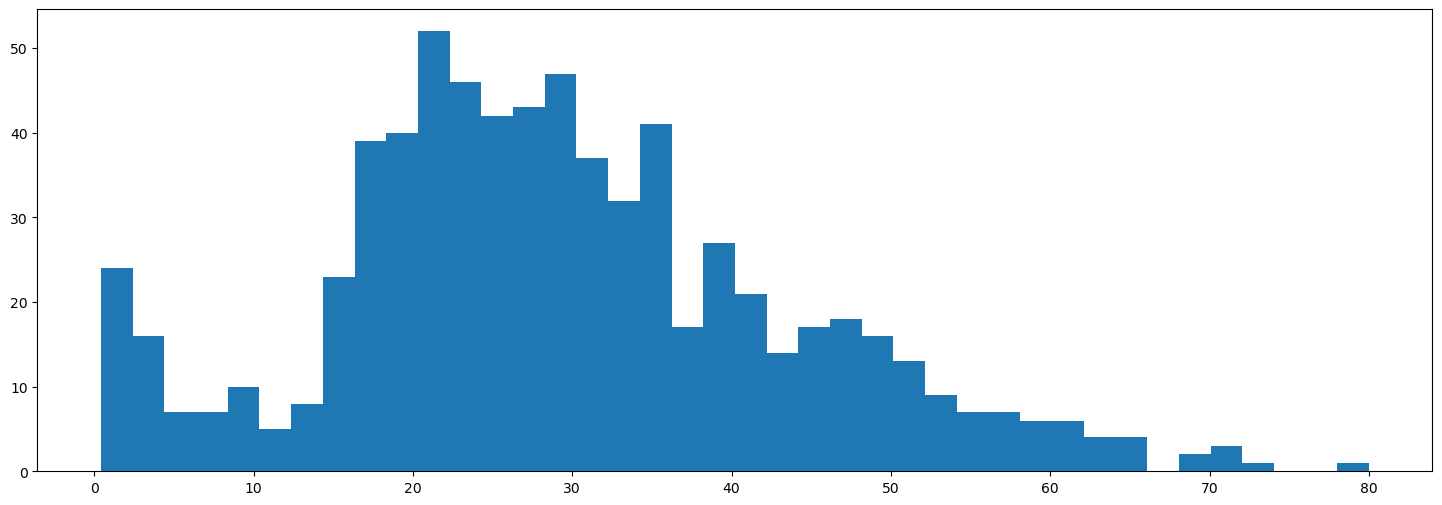

In [6]:
plt.figure(figsize=(18, 6))
plt.hist(df["Age"], bins=40)
plt.show()

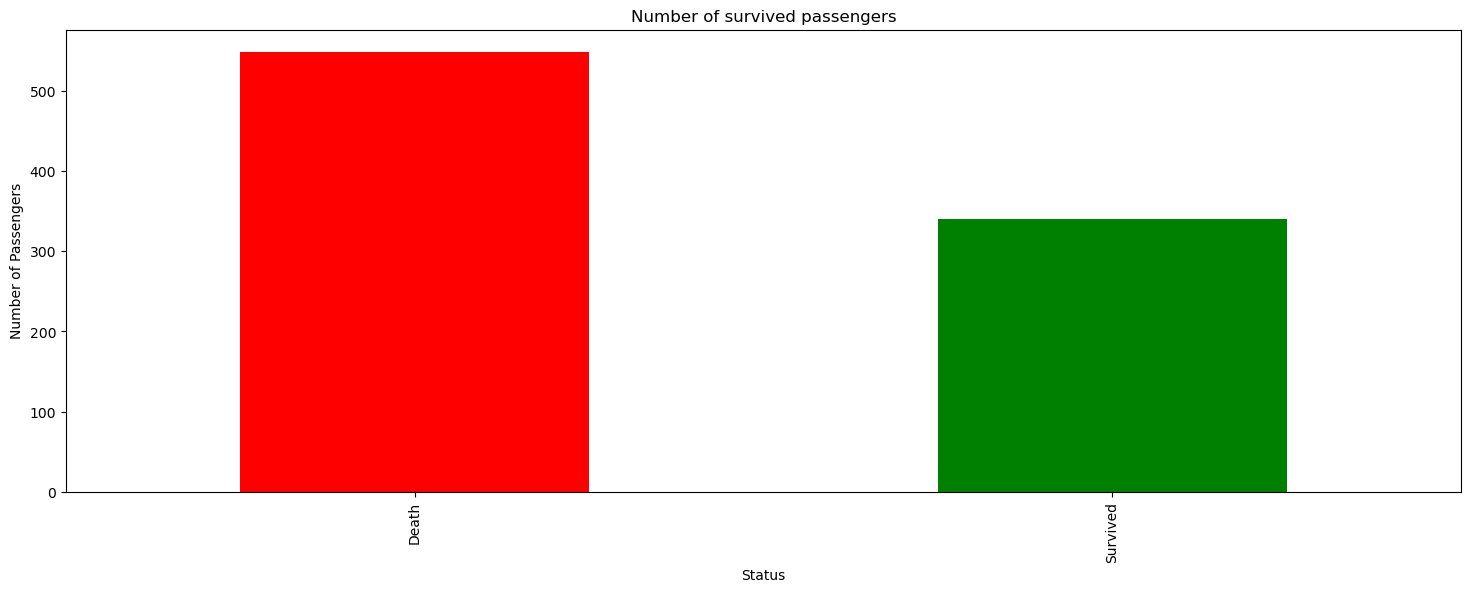

In [7]:
survived_counts = df["Survived"].value_counts().rename(index = {0:"Death", 1:"Survived"})

plt.figure(figsize=(18, 6))
survived_counts.plot(kind='bar', color=['red', 'green'])
plt.title("Number of survived passengers")
plt.ylabel('Number of Passengers')
plt.xlabel('Status')
plt.show()

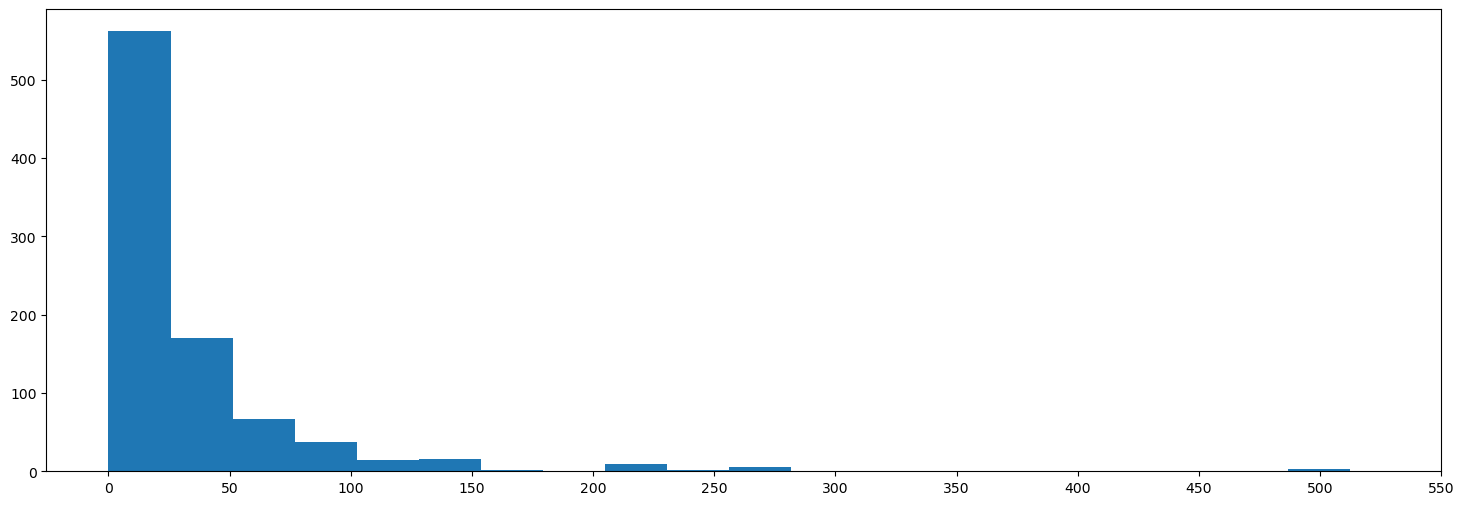

In [8]:
plt.figure(figsize = (18, 6))
plt.hist(df["Fare"], bins = 20)
plt.xticks(range(0, 600, 50))
plt.show()

In [9]:
a = df["Fare"].value_counts()
a.sort_values(ascending= False)

Fare
8.0500     43
13.0000    42
7.8958     38
7.7500     34
26.0000    31
           ..
13.8583     1
50.4958     1
5.0000      1
9.8458      1
10.5167     1
Name: count, Length: 247, dtype: int64

## Data preprocessing

In [10]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import KNNImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split

In [11]:
X = df.drop(columns='Survived')
y = df["Survived"]


In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier

In [14]:
categorical_cols = ['Sex', 'Embarked'] 
numerical_cols = ['Age', 'Fare']


preprocessor = ColumnTransformer(transformers=[
    ('cat', OneHotEncoder(drop='if_binary'), ['Sex', 'Embarked']),
    ('num', MinMaxScaler(), ['Age', 'Fare'])
], remainder='passthrough')

pipe = Pipeline([
    ('preprocess', preprocessor),
    ('impute', KNNImputer(n_neighbors=5))
])

Better_X_Train = pipe.fit_transform(X_train)
Better_X_Test = pipe.transform(X_test)

## Using various ml models

## Logistic Regression

In [15]:
LogRed = LogisticRegression()
LogRed.fit(Better_X_Train, y_train)
Train_log = round(LogRed.score(Better_X_Train, y_train) * 100, 3)
Test_log = round(LogRed.score(Better_X_Test, y_test) * 100, 3)
print("Train: ", Train_log)
print("Test: ", Test_log)

Train:  80.872
Test:  79.213


## RandomForest

In [16]:
rf = RandomForestClassifier(n_estimators= 10, max_depth= 3, min_samples_leaf=2, min_samples_split=2, random_state=67, max_features= 7)
rf.fit(Better_X_Train, y_train)
Train_rf = round(rf.score(Better_X_Train, y_train) * 100, 3)
Test_rf = round(rf.score(Better_X_Test, y_test) * 100, 3)
print("Train: ", Train_rf)
print("Test: ", Test_rf)

Train:  83.544
Test:  82.022


## GradientBoostingClassifier

In [17]:
GB = GradientBoostingClassifier(
    learning_rate=0.01,
    max_depth=10,
    max_features=0.8,
    min_samples_leaf=2,
    min_samples_split=2,
    n_estimators=100,
    subsample=0.4,
    random_state=42
)
GB.fit(Better_X_Train, y_train)
Train_GB = round(GB.score(Better_X_Train, y_train) *100, 3)
Test_GB = round(GB.score(Better_X_Test, y_test) * 100, 3)
print("Train: ", Train_GB)
print("Test: ", Test_GB)

Train:  90.999
Test:  80.899


## ExtraTree

In [18]:
ET = ExtraTreesClassifier(
    bootstrap=True,
    criterion='gini',
    max_features=0.65,
    min_samples_leaf=1,
    min_samples_split=6,
    n_estimators=100,
    random_state=42
)
ET.fit(Better_X_Train, y_train)
Train_ET = round(ET.score(Better_X_Train, y_train) * 100, 3)
Test_ET = round(ET.score(Better_X_Test, y_test) * 100, 3)
print("Train: ", Train_ET)
print("Test: ", Test_ET)

Train:  91.28
Test:  78.652


## Grid Search

In [19]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
# Gridsearch for Randomforest
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)
max_features_options = [5, 6, 7, 8, 9, 10]
param_grid = {
    'n_estimators': [100, 200, 400],
    'max_depth': [3, 5, 7, None],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split':[1, 2, 4],
    'max_features': max_features_options
}
grid = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=cv, scoring='accuracy')
grid.fit(Better_X_Train, y_train)
print(grid.best_params_, grid.best_score_)  # best_score_ is the CV estimate, more trustworthy than one split
best_rf = grid.best_estimator_
print("Test:", best_rf.score(Better_X_Test, y_test))

{'max_depth': None, 'max_features': 7, 'min_samples_leaf': 2, 'min_samples_split': 2, 'n_estimators': 100} 0.8481138579730129
Test: 0.797752808988764


In [20]:
# Gridsearch for Logistic Regression
cv2 = StratifiedKFold(n_splits = 5, shuffle=True, random_state= 67)
penalty = ['l1', 'l2']
param_grid_Log = {
    'penalty' : penalty,
    'C' : [0.01, 0.1, 1, 10, 100, 1000],
    'solver': ['lbfgs', 'liblinear', 'saga'],
    'max_iter': [100, 1000, 2500]
}
grid_2 = GridSearchCV(LogisticRegression(random_state = 67), param_grid_Log, cv = cv2, scoring= "accuracy")
grid_2.fit(Better_X_Train, y_train)
print(grid_2.best_params_, grid_2.best_score_)
best_LG = grid_2.best_estimator_
print("Test:", best_LG.score(Better_X_Test, y_test))

{'C': 10, 'max_iter': 100, 'penalty': 'l1', 'solver': 'liblinear'} 0.80592928198562
Test: 0.8033707865168539


In [21]:
# Gridsearch for GradientBoosting
cv3 = StratifiedKFold(n_splits = 5, shuffle=True, random_state= 67)
param_grid_GB = {
    'learning_rate' : [0.01, 0.05, 0.1],
    'max_depth' : [1, 3, 5, 7],
    'max_features' : [0.2, 0.4, 0.6, 0.8],
    'min_samples_leaf' : [1, 2, 3],
    'min_samples_split' : [2, 3],
    'n_estimators' : [100, 200, 400],
    'subsample' : [0.2, 0.4]
}
grid_3 = GridSearchCV(GradientBoostingClassifier(random_state = 67), param_grid_GB, cv = cv3, scoring = "accuracy")
grid_3.fit(Better_X_Train, y_train)
print(grid_3.best_params_, grid_3.best_score_)
best_GB = grid_3.best_estimator_
print("Test:", best_GB.score(Better_X_Test, y_test))

{'learning_rate': 0.01, 'max_depth': 7, 'max_features': 0.4, 'min_samples_leaf': 3, 'min_samples_split': 2, 'n_estimators': 400, 'subsample': 0.4} 0.8495321579828623
Test: 0.7865168539325843


In [22]:
# Gridsearch for ExtraTree
cv4 = StratifiedKFold(n_splits=5, shuffle=True, random_state=67)

param_grid_ET = {
    'n_estimators': [100, 200, 400, 600],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt', 'log2', 0.5, 0.8],
    'bootstrap': [False, True],
}

grid_4 = GridSearchCV(
    ExtraTreesClassifier(random_state=42),
    param_grid_ET,
    cv=cv4,
    scoring='accuracy',
    n_jobs=-1
)
grid_4.fit(Better_X_Train, y_train)
print(grid_4.best_params_, grid_4.best_score_)
best_ET = grid_4.best_estimator_
print("Test:", best_ET.score(Better_X_Test, y_test))

{'bootstrap': False, 'max_depth': None, 'max_features': 0.8, 'min_samples_leaf': 2, 'min_samples_split': 10, 'n_estimators': 100} 0.856584260809613
Test: 0.7752808988764045


In [24]:
models = pd.DataFrame({
    'Model': ['Logistic Regression', 'Random Forest',
              'ExtraTreesClassifier','GradientBoostingClassifier'],
    'Training Score' : [best_LG.score(Better_X_Train, y_train), best_rf.score(Better_X_Train, y_train),
                        best_ET.score(Better_X_Train, y_train), best_GB.score(Better_X_Train, y_train)],
    'Testing_score' : [best_LG.score(Better_X_Test, y_test), best_rf.score(Better_X_Test, y_test),
                       best_ET.score(Better_X_Test, y_test), best_GB.score(Better_X_Test, y_test)]})

models.sort_values(by='Testing_score', ascending=False)

,Model,Training Score,Testing_score
0,Logistic Regression,0.807314,0.803371
1,Random Forest,0.932489,0.797753
3,GradientBoostingClassifier,0.909986,0.786517
2,ExtraTreesClassifier,0.898734,0.775281


In [25]:
## Predict on the Kaggle test.csv (no Survived column) and build a submission file

# Load the competition test set
test_df = pd.read_csv("test.csv")

# Keep PassengerId for the submission format, then drop the same columns dropped from train
passenger_ids = test_df["PassengerId"]
test_df_clean = test_df.drop(["PassengerId", "Name", "Ticket", "Cabin"], axis="columns")

# IMPORTANT: transform only, never fit_transform here.
# This reuses the MinMaxScaler/OneHotEncoder/KNNImputer statistics learned from X_train —
# fit_transform would refit on test.csv and reintroduce the same leakage bug from before.
# (test.csv has 86 missing Age values and 1 missing Fare — the KNNImputer step in `pipe`
# handles both automatically, same as it did for X_test.)
Better_X_Kaggle = pipe.transform(test_df_clean)

# Swap `best_LG` for `best_rf` / `best_GB` / `best_ET` (or `LogRed` / `rf` / `GB` / `ET`
# for the manually-tuned versions) to compare submissions across models.
model_to_submit = best_LG
predictions = model_to_submit.predict(Better_X_Kaggle)

# Build submission file in Kaggle's expected format
submission = pd.DataFrame({
    "PassengerId": passenger_ids,
    "Survived": predictions
})
submission.to_csv("submission.csv", index=False)
submission.head()

,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,0
4,896,1
